# #**S-band Downlink Trade Study 2026-2027**

**Trade study v1 (built on the Ground Station Link Budget v2 model)**

Purpose: River asked for a *parametric* study, not a single design point. For the S-band DVB-S2 downlink, show what data rate and data volume are possible across modulation/coding, PA power (1-10 W), satellite antenna, pointing error, altitude and elevation. The output feeds the design matrix (feasibility, complexity, data rate) at the next systems meeting.

What is reused from v2 (unchanged)
- Constants (one Earth radius, 6371 km), `db`, `lin`, `fspl_db`, `therm_noise_dbm`, `tsys_at_lna_input`, `slant_range_km`, `prx_dBm`, `loss_sample`.
- `SAT_S`, `GS_S`, `DVB_S2` dictionaries, `build_s_spec`, the DVB-S2 threshold model (Es/N0 + implementation loss, pilots on), `p_target_grid` and `plot_heatmaps`.
- Section 5 reproduces the v2 S-band margin and best-MODCOD tables from the stored outputs as a regression check **before** any sweep runs.

What is new
- Full DVB-S2 MODCOD table (QPSK, 8PSK, 16APSK, 32APSK), plus GMSK and SX1280 LoRa as floor modes (River listed them).
- A max-symbol-rate solver: for each MODCOD, the highest $R_s$ that still closes with margin, capped by the RP2350/AFE7071 symbol-rate limit.
- Satellite antenna options and a satellite pointing-loss model (GNC error, optionally the nadir offset).
- Time-domain pass integration (fixed vs variable rate vs ACM) so rates become MB per pass and per day.
- Heatmaps, a tornado chart, Monte Carlo with GNC pointing error, and a Pareto filter.

Still PLACEHOLDER (inherited from v2, see its list): BPF, LNAs, satellite S-band antenna and losses, E200 noise figure, DVB-S2 implementation loss, GS antenna temperature.
New PLACEHOLDERS: `RS_MAX_SPS` (symbol-rate cap), antenna beamwidths and alternative antenna gains, passes per day, GNC error distribution, complexity scores.

# Link Budget (same model as v2)

$$
P_{rx} = P_{tx} - L_{\rm tx\,cable} + G_{\rm tx} - \mathrm{FSPL}(f,R) - L_{\rm atm} - L_{\rm pol} - L_{\rm point} + G_{\rm rx} - L_{\rm rx\,cable}
$$

#Free space path loss:
$$
\mathrm{FSPL\,[dB]} = 20\log_{10}\!\left(\frac{4\pi\,d\,f}{c}\right)
$$

#Noise density from the cascaded system temperature:
$$
N_{0}\,[\mathrm{dBm/Hz}] = 10\log_{10}\!\left(\frac{k\,T_{\rm sys}}{1\,\mathrm{mW}}\right) \approx -174 + 10\log_{10}\!\left(\frac{T_{\rm sys}}{290}\right)
$$

#DVB-S2 threshold model (v2):
$$
P_{R,\mathrm{req}}\,[\mathrm{dBm}] = N_{0} + 10\log_{10}(R_s) + \left(\frac{E_s}{N_0}\right)_{\mathrm{req}} + L_{\mathrm{impl}}, \qquad
\mathrm{Margin} = P_{rx} - P_{R,\mathrm{req}}
$$

#Information rate (pilots on):
$$
R_{\mathrm{info}} = R_s\,\eta_{\mathrm{MODCOD}}\,\rho_{\mathrm{pilot}}, \qquad
\rho_{\mathrm{pilot}} = \frac{N_{\rm frame}}{N_{\rm frame} + 36\left\lfloor (N_{\rm slots}-1)/16 \right\rfloor}
$$

where $N_{\rm frame} = 90(1 + N_{\rm slots})$ symbols and $N_{\rm slots} = 64800/(90\,m)$ for a normal FECFRAME with $m$ bits per symbol. For QPSK this gives $32490/33282$, the v2 constant.

---

# New equations for the trade study

#Maximum symbol rate that closes (the "power-limited" rate):
Solve the threshold model for $R_s$ with required margin $M$:

$$
R_{s,\mathrm{pwr}} = 10^{\left(P_{rx} - M - N_0 - (E_s/N_0)_{\mathrm{req}} - L_{\mathrm{impl}}\right)/10}
$$

and cap it by what the RP2350/AFE7071/SDR chain can actually generate:

$$
R_s = \min\!\left(R_{s,\mathrm{pwr}},\; R_{s,\max}\right), \qquad R_{\mathrm{info}} = R_s\,\eta\,\rho_{\mathrm{pilot}}
$$

Each MODCOD therefore has a power-limited regime (rate grows with $P_{rx}$) and a hardware-limited regime (rate flat at $R_{s,\max}\eta\rho$). High-order MODCODs only pay off once the link is in the second regime.

#Satellite pointing loss (parabolic main-lobe approximation):
$$
L_{\mathrm{pt,sat}}(\theta) \approx 12\left(\frac{\theta}{\theta_{3\mathrm{dB}}}\right)^2\ \mathrm{[dB]} \quad (\text{capped})
$$

with off-boresight angle $\theta$ set by the pointing model:

$$
\theta = \begin{cases} 0 & \text{`none` (v2 behavior)}\\ \theta_{\rm err} & \text{`steered` (GNC slews the patch at the GS)}\\ \eta(\epsilon) + \theta_{\rm err} & \text{`nadir` (body-fixed, no slew)} \end{cases}
$$

$$
\eta(\epsilon) = \arcsin\!\left(\frac{R_E}{R_E+h}\cos\epsilon\right)
$$

A higher-gain antenna has a narrower $\theta_{3\mathrm{dB}}$, so it is the one that punishes GNC error.

#Pass geometry (circular orbit, Earth rotation ignored):
Earth central angle for elevation $\epsilon$:

$$
\lambda(\epsilon) = \arccos\!\left(\frac{R_E}{R_E+h}\cos\epsilon\right) - \epsilon
$$

A pass with peak elevation $\epsilon_{\max}$ and ground-station mask $\epsilon_{\min}$ satisfies $\cos\lambda(t) = \cos\lambda_{\min}\cos(\omega t)$ with $\lambda_{\min}=\lambda(\epsilon_{\max})$:

$$
\Delta_{\max} = \arccos\!\left(\frac{\cos\lambda(\epsilon_{\min})}{\cos\lambda_{\min}}\right), \qquad T_{\rm pass} = \frac{2\Delta_{\max}}{\omega}, \qquad \omega = \sqrt{\frac{\mu}{(R_E+h)^3}}
$$

#Data volume:
$$
D_{\rm pass} = \sum_k R_{\rm info}[k]\,\Delta t, \qquad D_{\rm day} = N_{\rm passes/day}\,D_{\rm pass}
$$

- **Fixed:** one rate for the whole pass, $R_{\rm fixed} = \min_k R_{\rm info}[k]$ (closes at the worst step).
- **Variable:** same MODCOD, symbol rate follows the link each step.
- **ACM:** best MODCOD every step, $\sum_k \max_{\rm modes} R_{\rm info}[k]\,\Delta t$.

#Floor modes:
GMSK uses $\eta = 1$ and a required $E_s/N_0 = E_b/N_0 \approx 10.5$ dB (9.6 dB coherent MSK plus about 1 dB, **assumption**). SX1280 LoRa is sensitivity-based, as in v2:

$$
P_{R,\mathrm{req}} = N_0 + 10\log_{10}(B) + \mathrm{SNR}_{\rm req}(SF), \qquad R_b = SF\,\frac{B}{2^{SF}}\,CR
$$

---

## **`Background:`**
River's example: *QPSK with a SAMWISE-like patch at 2 W closes for about 2 MB/s (16 Mbit/s)*. Section 5 checks it against this model instead of assuming it. "All bounds" means we sweep ranges rather than design within a power or mass budget; only the OOMs are known (S-band PA 1-10 W, the 1.9 m dish).

**Setup:**

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LogNorm

# Units
GHz, MHz, kHz, km = 1e9, 1e6, 1e3, 1e3

C   = 299_792_458.0       # speed of light [m/s]
MU  = 3.986004418e14      # Earth gravitational parameter [m^3/s^2]
R_EARTH_KM = 6371.0       # mean Earth radius, used everywhere (same as v2)
R_EARTH_M  = R_EARTH_KM*km
T0  = 290.0               # reference temperature [K]
KT0_DBM_PER_HZ = -174.0   # k*T0 at 290 K [dBm/Hz] (this is kT0, not Boltzmann's k)

# Carrier frequency (S-band, satellite -> GS only)
f_Hz_S = 2.427*GHz

**S-band downlink specs (v2 values, unchanged):**

```
SAT: CM5 -> RP2350 (DVB-S2 baseband) -> AFE7071 -> PA (baseline 2 W) -> patch
GS:  1.9 m dish -> helix feed -> LNA (at feed) -> coax -> receiver (AntSDR E200 / gr-dvbs2rx assumed)
```

The DVB-S2 table is extended past QPSK using the same source (ETSI EN 302 307-1 Table 13, ideal $E_s/N_0$ at QEF, normal FECFRAME, AWGN). Verify the 8PSK/APSK numbers against the standard before quoting them. **Note:** if your hardware is only built for QPSK, set `INCLUDE_HIGH_ORDER = False` below.

In [ ]:
# Our testing altitudes / elevations (v2)
altitudes_km      = [400, 600, 800, 1000]
elevations_degree = [0, 5, 10, 20, 30, 45, 60, 90]

# All variables below should be labelled FIXED (decided and will not change), ASSUMED (decided but may change), or TBC (undecided and dependent on outcome of this link budget).
# All variables should have a name at the end so that we can check in on any questions regarding the variable
# e.g. alt_km = 550.0,   # satellite altitude; systems meeting 12 Oct 2026 (FIXED, Joel)

SAT_S = dict(
    pa_out_W     = 2.0,    # VARIABLE: satellite S-band PA output, baseline 2 W (Unknown, Unknown)
    loss_dB      = 0.5,    # PLACEHOLDER: PA -> antenna (coax, connectors, any filter) (Unknown, Unknown)
    ant_gain_dBi = 5.0,    # Taoglas WPC.25A.07 patch -- CONFIRM, and its polarization (assumed linear) (Unknown, Unknown)
)

GS_S = dict(
    dish_gain_dBi = 31.4,   # 1.9 m mesh dish (~55% efficiency gives ~31 dBi at 2.427 GHz) (Unknown, Unknown)
    feed_loss_dB  = 0.2,    # feed -> LNA, LNA mounted at the feed (Unknown, Unknown)
    T_ant_K       = 100.0,  # PLACEHOLDER: sky + mesh/spillover; climbs at low elevation (Unknown, Unknown)
    lna_nf_dB     = 0.8,    # PLACEHOLDER (Unknown, Unknown)
    lna_gain_dB   = 30.0,   # PLACEHOLDER (Unknown, Unknown)
    post_loss_dB  = 1.0,    # PLACEHOLDER: LNA -> receiver coax (receiver on the roof) (Unknown, Unknown)
    rx_nf_dB      = 4.0,    # PLACEHOLDER: AntSDR E200 (AD9363), approx (Unknown, Unknown)
    pol_loss_dB   = 3.0,    # linear sat patch -> circular helix feed (Unknown, Unknown)
    point_loss_dB = 1.0,    # GS dish pointing (Unknown, Unknown)
    atm_loss_dB   = 0.2,    # atmospheric loss (Unknown, Unknown)
)

DVB_S2 = dict(
    Rs_sps       = 1e6,        # v2 baseline symbol rate (the trade study varies this, see RS_MAX_SPS) (Unknown, Unknown)
    modcod       = "QPSK 1/2", # looking into VCM downlink with varying MODCOD (ASSUMED, Joel)
    impl_loss_dB = 1.5,        # PLACEHOLDER: modem implementation loss (Unknown, Unknown)
    pilots       = True,       # (Unknown, Unknown)
)

# Trade-study knobs (everything the sweeps read by default)
TRADE = dict(
    alt_km          = 550.0,   # satellite altitude; systems meeting 12 Oct 2026 (FIXED, Joel)
    min_el_deg      = 10.0,    # GS elevation mask (Unknown, Unknown)
    max_el_deg      = 45.0,    # peak elevation of the pass being evaluated (Unknown, Unknown)
    eval_el_deg     = 10.0,    # elevation used for the single-point heatmaps (worst-case-ish) (Unknown, Unknown)
    passes_per_day  = 4.0,     # PLACEHOLDER: usable passes/day (get from SGP4/STK for the GS) (Unknown, Unknown)
    margin_dB       = 3.0,     # required margin for rate solving (v2 best-MODCOD table uses 3 dB) (Unknown, Unknown)
    Rs_max_sps      = 8e6,     # PLACEHOLDER: max symbol rate RP2350/AFE7071/SDR can sustain (v2 repo tested 8 Msym/s) (Unknown, Unknown)
    ant             = "Taoglas patch (baseline)", # (Unknown, Unknown)
    pointing_err_deg= 5.0,     # GNC pointing requirement quoted by River (Unknown, River)
    pointing        = "steered",   # "none" (v2) | "steered" (GNC slews at GS) | "nadir" (body-fixed) (Unknown, Unknown)
    gnc_req_deg     = 5.0,     # (Unknown, Unknown)
    pa_struct_W     = 3.0,     # River: "if structures can handle the 3 W" (Unknown, River)
)
POINT_LOSS_CAP_DB = 25.0       # parabolic pointing-loss model is only valid near boresight (Unknown, Unknown)

# (gain dBi, 3 dB beamwidth deg).  Baseline gain comes from SAT_S; the rest are PLACEHOLDER candidates.
SAT_ANTENNAS = {
    "Near-omni (turnstile)":    (2.0, 120.0),
    "Taoglas patch (baseline)": (SAT_S["ant_gain_dBi"], 80.0),   # beamwidth PLACEHOLDER: read the datasheet (Unknown, Unknown)
    "Patch array 2x2":          (11.0, 40.0),
    "Helical (7-turn)":         (13.0, 30.0),
}

INCLUDE_HIGH_ORDER = True # (Unknown, Unknown)

SyntaxError: incomplete input (511721495.py, line 5)

In [ ]:
#General Equations and Conversions  (v2 helpers, unchanged)

def db(x):  return 10*np.log10(x)                          # linear -> dB
def lin(x): return 10**(np.asarray(x, dtype=float)/10)     # dB -> linear

def fspl_db(d_m, f_hz):
    '''Free space path loss [dB].'''
    return 20*np.log10(4*np.pi*d_m*f_hz/C)

def therm_noise_dbm(T_sys_K, B_Hz):
    '''Noise power kTB [dBm].'''
    return KT0_DBM_PER_HZ + 10*np.log10(T_sys_K/T0) + 10*np.log10(B_Hz)

def nf_to_te(nf_dB):
    '''Noise figure [dB] -> equivalent noise temperature [K].'''
    return T0*(lin(nf_dB) - 1)

def tsys_at_lna_input(T_ant_K, pre_loss_dB, lna_nf_dB, lna_gain_dB, post_loss_dB, rx_nf_dB):
    '''System noise temperature referred to the LNA input [K].
    Chain: antenna -> passive loss (pre_loss) -> LNA -> passive loss (post_loss) -> receiver.'''
    L_pre   = lin(pre_loss_dB)
    T_in    = T_ant_K/L_pre + T0*(1 - 1/L_pre)
    L_post  = lin(post_loss_dB)
    Te_post = T0*(L_post - 1) + L_post*nf_to_te(rx_nf_dB)
    return T_in + nf_to_te(lna_nf_dB) + Te_post/lin(lna_gain_dB)

# Required SNR per spreading factor (demod limit) https://www.thethingsnetwork.org/docs/lorawan/rssi-and-snr/
LORA_SNR = {6: -5, 7: -7.5, 8: -10, 9: -12.5, 10: -15, 11: -17.5, 12: -20}
def lora_demod_snr(sf): return LORA_SNR[int(sf)]
def lora_bitrate_bps(sf, bw_hz=125e3, cr=4/5):
    return sf*(bw_hz/2**sf)*cr

def slant_range_km(alt_km, elev_deg):
    e = np.radians(elev_deg)
    r = R_EARTH_KM
    return np.sqrt((r + alt_km)**2 - (r*np.cos(e))**2) - r*np.sin(e)

def prx_dBm(alt_km, elev_deg, s, f_hz, **override):
    '''Received power [dBm] for link spec `s` at frequency f_hz.
    Any spec key can be overridden (the Monte Carlo passes arrays this way).'''
    p = {**s, **override}
    d_m = slant_range_km(alt_km, elev_deg)*km
    return (p["tx_power_dBm"] - p["tx_loss_dB"] + p["tx_gain_dBi"]
            - fspl_db(d_m, f_hz)
            - p["L_atm_dB"] - p["L_pol_dB"] - p["L_point_dB"]
            + p["rx_gain_dBi"] - p["rx_loss_dB"])

def loss_sample(rng, nominal_dB, std_dB, n):
    '''Random loss that can't go below 0 dB (a loss is never a gain).'''
    return np.clip(nominal_dB + rng.normal(0, std_dB, n), 0, None)

**New geometry helpers.** Pass profile for a pass with a given peak elevation. A low-peak pass is short and far; an overhead pass is long and close. Earth rotation is ignored (small effect for a trade study; replace with SGP4/STK passes later).

In [ ]:
def central_angle(el_rad, h_m):
    return np.arccos(R_EARTH_M/(R_EARTH_M + h_m)*np.cos(el_rad)) - el_rad

def elevation_from_central_angle(lam, h_m):
    return np.arctan2(np.cos(lam) - R_EARTH_M/(R_EARTH_M + h_m), np.sin(lam))

def nadir_angle_deg(alt_km, elev_deg):
    '''Angle off nadir seen from the satellite for a GS at elevation elev_deg.'''
    e = np.radians(elev_deg)
    return np.degrees(np.arcsin(R_EARTH_KM/(R_EARTH_KM + alt_km)*np.cos(e)))

def pass_profile(alt_km, min_el_deg, max_el_deg, dt=1.0):
    h = alt_km*km
    max_el_deg = max(max_el_deg, min_el_deg + 1e-3)
    lam_min  = central_angle(np.radians(max_el_deg), h)     # closest approach
    lam_mask = central_angle(np.radians(min_el_deg), h)     # GS mask
    omega = np.sqrt(MU/(R_EARTH_M + h)**3)
    Dmax = np.arccos(np.clip(np.cos(lam_mask)/np.cos(lam_min), -1, 1))
    T = 2*Dmax/omega
    t = np.arange(-T/2, T/2 + dt/2, dt)
    D = np.clip(omega*t, -Dmax, Dmax)
    lam = np.arccos(np.clip(np.cos(lam_min)*np.cos(D), -1, 1))
    return dict(t=t - t[0], T=T, el_deg=np.degrees(elevation_from_central_angle(lam, h)))

for me in (15, 30, 60, 90):
    p = pass_profile(600, 10, me)
    print(f"600 km, peak el {me:>2} deg: pass duration {p['T']/60:4.1f} min")

600 km, peak el 15 deg: pass duration  4.9 min
600 km, peak el 30 deg: pass duration  7.5 min
600 km, peak el 60 deg: pass duration  8.4 min
600 km, peak el 90 deg: pass duration  8.5 min


In [ ]:
# ETSI EN 302 307-1 Table 13: ideal Es/N0 [dB] at QEF, spectral efficiency [bit/symbol, no pilots], bits/symbol m
DVBS2_TABLE = {
    "QPSK 1/4": (-2.35, 0.490, 2), "QPSK 1/3": (-1.24, 0.656, 2), "QPSK 2/5": (-0.30, 0.789, 2),
    "QPSK 1/2": ( 1.00, 0.988, 2), "QPSK 3/5": ( 2.23, 1.188, 2), "QPSK 2/3": ( 3.10, 1.322, 2),
    "QPSK 3/4": ( 4.03, 1.487, 2), "QPSK 4/5": ( 4.68, 1.587, 2), "QPSK 5/6": ( 5.18, 1.655, 2),
    "QPSK 8/9": ( 6.20, 1.766, 2), "QPSK 9/10":( 6.42, 1.789, 2),
    "8PSK 3/5": ( 5.50, 1.779, 3), "8PSK 2/3": ( 6.62, 1.981, 3), "8PSK 3/4": ( 7.91, 2.228, 3),
    "8PSK 5/6": ( 9.35, 2.479, 3), "8PSK 8/9": (10.69, 2.646, 3), "8PSK 9/10": (10.98, 2.679, 3),
    "16APSK 2/3": ( 8.97, 2.637, 4), "16APSK 3/4": (10.21, 2.967, 4), "16APSK 4/5": (11.03, 3.166, 4),
    "16APSK 5/6": (11.61, 3.300, 4), "16APSK 8/9": (12.89, 3.523, 4), "16APSK 9/10": (13.13, 3.567, 4),
    "32APSK 3/4": (12.73, 3.703, 5), "32APSK 4/5": (13.64, 3.952, 5), "32APSK 5/6": (14.28, 4.120, 5),
    "32APSK 8/9": (15.69, 4.398, 5), "32APSK 9/10": (16.05, 4.453, 5),
}
if not INCLUDE_HIGH_ORDER:
    DVBS2_TABLE = {k: v for k, v in DVBS2_TABLE.items() if k.startswith("QPSK")}
DVBS2_QPSK = {k: v[:2] for k, v in DVBS2_TABLE.items() if k.startswith("QPSK")}   # v2 name, same numbers

def pilot_factor(m, normal=True):
    '''Pilots-on frame efficiency: 90-symbol PLHEADER, 90-symbol slots, 36 pilot symbols per 16 slots.'''
    slots = (64800 if normal else 16200)/m/90
    nopilot = 90*(1 + slots)
    return nopilot/(nopilot + 36*np.floor((slots - 1)/16))

assert abs(pilot_factor(2) - 32490/33282) < 1e-12, "QPSK pilot factor should match the v2 constant"

def build_modes(lora_bw=812.5e3, lora_cr=4/5):
    '''One row per mode. kind: "dvbs2" and "gmsk" are linear (solve for Rs); "lora" is a fixed-rate sensitivity mode.'''
    rows = []
    for name, (esn0, eta, m) in DVBS2_TABLE.items():
        rows.append(dict(name=name, family=name.split()[0], kind="dvbs2", thr_dB=esn0, eta=eta,
                         pilot_f=pilot_factor(m), uses_impl=True, bw_hz=np.nan, fixed_rate=np.nan))
    rows.append(dict(name="GMSK/GFSK", family="GMSK", kind="gmsk", thr_dB=10.5, eta=1.0, pilot_f=1.0,
                     uses_impl=False, bw_hz=np.nan, fixed_rate=np.nan))   # 10.5 dB assumed (includes real-world loss)
    for sf in range(7, 13):                                               # SX1280 S-band LoRa, floor mode
        rows.append(dict(name=f"LoRa SF{sf}", family="LoRa", kind="lora", thr_dB=lora_demod_snr(sf), eta=np.nan,
                         pilot_f=np.nan, uses_impl=False, bw_hz=lora_bw, fixed_rate=lora_bitrate_bps(sf, lora_bw, lora_cr)))
    return pd.DataFrame(rows)

MODES = build_modes()
MODE = {r["name"]: r for _, r in MODES.iterrows()}
display(MODES[["name", "kind", "thr_dB", "eta", "pilot_f", "fixed_rate"]].round(3))

,name,kind,thr_dB,eta,pilot_f,fixed_rate
0,QPSK 1/4,dvbs2,-2.35,0.490,0.976,NaN
1,QPSK 1/3,dvbs2,-1.24,0.656,0.976,NaN
2,QPSK 2/5,dvbs2,-0.30,0.789,0.976,NaN
3,QPSK 1/2,dvbs2,1.00,0.988,0.976,NaN
4,QPSK 3/5,dvbs2,2.23,1.188,0.976,NaN
5,QPSK 2/3,dvbs2,3.10,1.322,0.976,NaN
6,QPSK 3/4,dvbs2,4.03,1.487,0.976,NaN
7,QPSK 4/5,dvbs2,4.68,1.587,0.976,NaN
8,QPSK 5/6,dvbs2,5.18,1.655,0.976,NaN
9,QPSK 8/9,dvbs2,6.20,1.766,0.976,NaN


**Link functions.** `build_s_spec` is the v2 function unchanged. New: `sat_point_loss_db` (satellite-side pointing, added to the GS dish pointing already in `L_point_dB`), `prx_S` (received power for any antenna/power/pointing setup), and `solve_mode` (max symbol rate and info rate for one mode).

In [ ]:
def build_s_spec(sat=None, g=None):
    sat, g = sat or SAT_S, g or GS_S
    return dict(
        tx_power_dBm = 10*np.log10(sat["pa_out_W"]*1e3),
        tx_loss_dB   = sat["loss_dB"],
        tx_gain_dBi  = sat["ant_gain_dBi"],
        rx_gain_dBi  = g["dish_gain_dBi"],
        rx_loss_dB   = g["feed_loss_dB"],
        L_atm_dB     = g["atm_loss_dB"],
        L_pol_dB     = g["pol_loss_dB"],
        L_point_dB   = g["point_loss_dB"],
        T_sys_K      = tsys_at_lna_input(g["T_ant_K"], g["feed_loss_dB"], g["lna_nf_dB"],
                                         g["lna_gain_dB"], g["post_loss_dB"], g["rx_nf_dB"]),
    )

spec_DL_S = build_s_spec()

def sat_point_loss_db(alt_km, elev_deg, ant, err_deg, pointing):
    '''Satellite antenna pointing loss [dB]. err_deg may be an array (Monte Carlo).'''
    bw3  = SAT_ANTENNAS[ant][1]
    elev = np.asarray(elev_deg, dtype=float)
    if pointing == "none":
        return np.zeros_like(elev + err_deg)
    if pointing == "steered":
        theta = np.zeros_like(elev) + err_deg
    elif pointing == "nadir":
        theta = nadir_angle_deg(alt_km, elev) + err_deg
    else:
        raise ValueError(f"Invalid pointing model: {pointing}")
    return np.minimum(12*(theta/bw3)**2, POINT_LOSS_CAP_DB)

def prx_S(alt_km, elev_deg, p_W=None, ant=None, err_deg=None, pointing=None, sat=None, g=None, **ov):
    '''Received S-band power [dBm] and GS T_sys [K] for one configuration.'''
    ant      = ant or TRADE["ant"]
    err_deg  = TRADE["pointing_err_deg"] if err_deg is None else err_deg
    pointing = pointing or TRADE["pointing"]
    sat = dict(sat or SAT_S, ant_gain_dBi=SAT_ANTENNAS[ant][0])
    if p_W is not None:
        sat["pa_out_W"] = p_W
    s = build_s_spec(sat, g)
    L_point = ov.pop("L_point_dB", s["L_point_dB"]) + sat_point_loss_db(alt_km, elev_deg, ant, err_deg, pointing)
    return prx_dBm(alt_km, elev_deg, s, f_Hz_S, L_point_dB=L_point, **ov), s["T_sys_K"]

def solve_mode(prx, tsys, mode, margin_dB=None, Rs_cap=None, impl_dB=None):
    '''Max info rate [bit/s] and symbol rate [sym/s] that close with margin_dB for one mode.
    Returns (rate, Rs). Rate is 0 where the mode does not close.'''
    margin_dB = TRADE["margin_dB"] if margin_dB is None else margin_dB
    Rs_cap    = TRADE["Rs_max_sps"] if Rs_cap is None else Rs_cap
    impl_dB   = DVB_S2["impl_loss_dB"] if impl_dB is None else impl_dB
    prx, tsys = np.asarray(prx, dtype=float), np.asarray(tsys, dtype=float)
    if mode["kind"] == "lora":
        req = therm_noise_dbm(tsys, mode["bw_hz"]) + mode["thr_dB"]
        ok  = (prx - margin_dB) >= req
        return np.where(ok, mode["fixed_rate"], 0.0), np.where(ok, mode["bw_hz"], 0.0)
    N0   = therm_noise_dbm(tsys, 1.0)                                  # dBm/Hz
    imp  = impl_dB if mode["uses_impl"] else 0.0
    Rs   = np.minimum(10**((prx - margin_dB - N0 - mode["thr_dB"] - imp)/10), Rs_cap)
    pf   = mode["pilot_f"] if DVB_S2["pilots"] else 1.0
    return Rs*mode["eta"]*pf, Rs

def margin_S_dB(alt_km, elev_deg, modcod=None, Rs=None, **kw):
    '''v2-style margin for a fixed MODCOD and symbol rate.'''
    modcod = modcod or DVB_S2["modcod"]; Rs = DVB_S2["Rs_sps"] if Rs is None else Rs
    prx, tsys = prx_S(alt_km, elev_deg, **kw)
    return prx - (therm_noise_dbm(tsys, Rs) + MODE[modcod]["thr_dB"] + DVB_S2["impl_loss_dB"])

def best_rate_bps(prx, tsys, modes=None, **kw):
    '''ACM: best info rate over the mode set at each point.'''
    modes = MODES if modes is None else modes
    return np.max([solve_mode(prx, tsys, m, **kw)[0] for _, m in modes.iterrows()], axis=0)

**Regression check against v2.** With `pointing="none"` this model must reproduce the v2 S-band tables. The numbers below were copied from the stored outputs of the v2 notebook (margin table for QPSK 1/2, 1 Msym/s, 2 W, and the best-QPSK-MODCOD tables at a fixed 1 and 8 Msym/s). If this cell fails, do not trust any sweep.

In [ ]:
V2_MARGIN = pd.DataFrame(
    [[11.0, 13.1, 15.1, 18.4, 20.9, 23.4, 25.0, 26.2],
     [ 9.2, 10.9, 12.5, 15.4, 17.6, 20.0, 21.5, 22.7],
     [ 7.9,  9.3, 10.8, 13.3, 15.3, 17.6, 19.1, 20.2],
     [ 6.9,  8.2,  9.4, 11.7, 13.6, 15.8, 17.2, 18.2]],
    index=altitudes_km, columns=elevations_degree)
V2_RATE_1M = pd.DataFrame(
    [[1.75]*8, [1.75]*8,
     [1.62, 1.75, 1.75, 1.75, 1.75, 1.75, 1.75, 1.75],
     [1.55, 1.62, 1.75, 1.75, 1.75, 1.75, 1.75, 1.75]], index=altitudes_km, columns=elevations_degree)
V2_RATE_8M = pd.DataFrame(
    [[6.16, 7.72, 11.61, 13.97, 13.97, 13.97, 13.97, 13.97],
     [3.83, 6.16,  7.72, 11.61, 13.97, 13.97, 13.97, 13.97],
     [0.00, 3.83,  6.16,  9.28, 11.61, 13.97, 13.97, 13.97],
     [0.00, 0.00,  3.83,  6.16,  9.28, 12.39, 12.92, 13.97]], index=altitudes_km, columns=elevations_degree)

def best_qpsk_rate_fixed_Rs(alt_km, elev_deg, Rs, min_margin_dB=3.0):
    '''v2 algorithm: fixed symbol rate, pick the best QPSK MODCOD that still has min_margin_dB.'''
    best = 0.0
    for mc in DVBS2_QPSK:
        if margin_S_dB(alt_km, elev_deg, mc, Rs=Rs, pointing="none") >= min_margin_dB:
            best = max(best, Rs*MODE[mc]["eta"]*MODE[mc]["pilot_f"]/1e6)
    return best

mine_margin = pd.DataFrame({e: [margin_S_dB(h, e, pointing="none") for h in altitudes_km] for e in elevations_degree}, index=altitudes_km)
mine_1m = pd.DataFrame({e: [best_qpsk_rate_fixed_Rs(h, e, 1e6) for h in altitudes_km] for e in elevations_degree}, index=altitudes_km)
mine_8m = pd.DataFrame({e: [best_qpsk_rate_fixed_Rs(h, e, 8e6) for h in altitudes_km] for e in elevations_degree}, index=altitudes_km)

for name, mine, ref, tol in (("margin", mine_margin, V2_MARGIN, 0.051), ("best QPSK, 1 Msym/s", mine_1m, V2_RATE_1M, 0.0051),
                             ("best QPSK, 8 Msym/s", mine_8m, V2_RATE_8M, 0.0051)):
    err = (mine - ref).abs().to_numpy().max()
    print(f"{name:22s}: max |mine - v2| = {err:.4f}  ->  {'OK' if err <= tol else 'MISMATCH'}")
    assert err <= tol, f"{name} does not reproduce v2"
print("\nBaseline reproduced: the trade-study model matches v2 when the extra pointing model is off.")

margin                : max |mine - v2| = 0.0480  ->  OK
best QPSK, 1 Msym/s   : max |mine - v2| = 0.0044  ->  OK
best QPSK, 8 Msym/s   : max |mine - v2| = 0.0049  ->  OK

Baseline reproduced: the trade-study model matches v2 when the extra pointing model is off.


**River's example, checked instead of assumed.** *QPSK with a patch at 2 W closes for about 2 MB/s = 16 Mbit/s.* For each DVB-S2 MODCOD, the symbol rate needed for 16 Mbit/s is

$$
R_{s,\rm needed} = \frac{R_{\rm target}}{\eta\,\rho_{\rm pilot}}
$$

If that exceeds `RS_MAX_SPS` the MODCOD cannot reach 16 Mbit/s regardless of power. For those that can, the margin is shown at three elevations. Steered pointing, 5 deg GNC error, 2 W, 600 km.

In [ ]:
R_TARGET_BPS = 16e6     # River's 2 MB/s
rows = []
for _, m in MODES[MODES.kind == "dvbs2"].iterrows():
    Rs_need = R_TARGET_BPS/(m["eta"]*m["pilot_f"])
    row = dict(mode=m["name"], Rs_needed_Msps=Rs_need/1e6, under_cap=Rs_need <= TRADE["Rs_max_sps"])
    for e in (10, 45, 90):
        row[f"margin_{e}deg_dB"] = margin_S_dB(TRADE["alt_km"], e, m["name"], Rs=Rs_need, p_W=2.0)
    rows.append(row)
df_river = pd.DataFrame(rows)
print(f"Symbol-rate cap = {TRADE['Rs_max_sps']/1e6:g} Msym/s ({TRADE['alt_km']:g} km, 2 W, {TRADE['ant']}, {TRADE['pointing']} {TRADE['pointing_err_deg']} deg)")
print(df_river[df_river.under_cap].round(2).to_string(index=False))
print("\nQPSK modes that need more than the cap:",
      ", ".join(df_river[(~df_river.under_cap) & df_river["mode"].str.startswith("QPSK")]["mode"]))

Symbol-rate cap = 8 Msym/s (600 km, 2 W, Taoglas patch (baseline), steered 5.0 deg)
       mode  Rs_needed_Msps  under_cap  margin_10deg_dB  margin_45deg_dB  margin_90deg_dB
   8PSK 3/4            7.35       True            -3.10             4.40             7.05
   8PSK 5/6            6.60       True            -4.08             3.42             6.08
   8PSK 8/9            6.19       True            -5.13             2.36             5.02
  8PSK 9/10            6.11       True            -5.37             2.13             4.79
 16APSK 2/3            6.21       True            -3.43             4.06             6.72
 16APSK 3/4            5.52       True            -4.16             3.34             5.99
 16APSK 4/5            5.18       True            -4.70             2.80             5.46
 16APSK 5/6            4.97       True            -5.10             2.40             5.06
 16APSK 8/9            4.65       True            -6.10             1.40             4.06
16APSK 9/10     

# Sweeps

Slice the big matrix instead of plotting the full cross product.

- **A:** MODCOD $\times$ PA power at one altitude and a low elevation.
- **B:** antenna $\times$ GNC pointing error, for the two pointing models. This is the GNC dependency River asked about.
- **C:** altitude $\times$ elevation, best MODCOD, for two symbol-rate caps: shows where the link is power-limited vs hardware-limited.

Rates are shown in Mbit/s. A dash means that MODCOD does not close with the required margin.

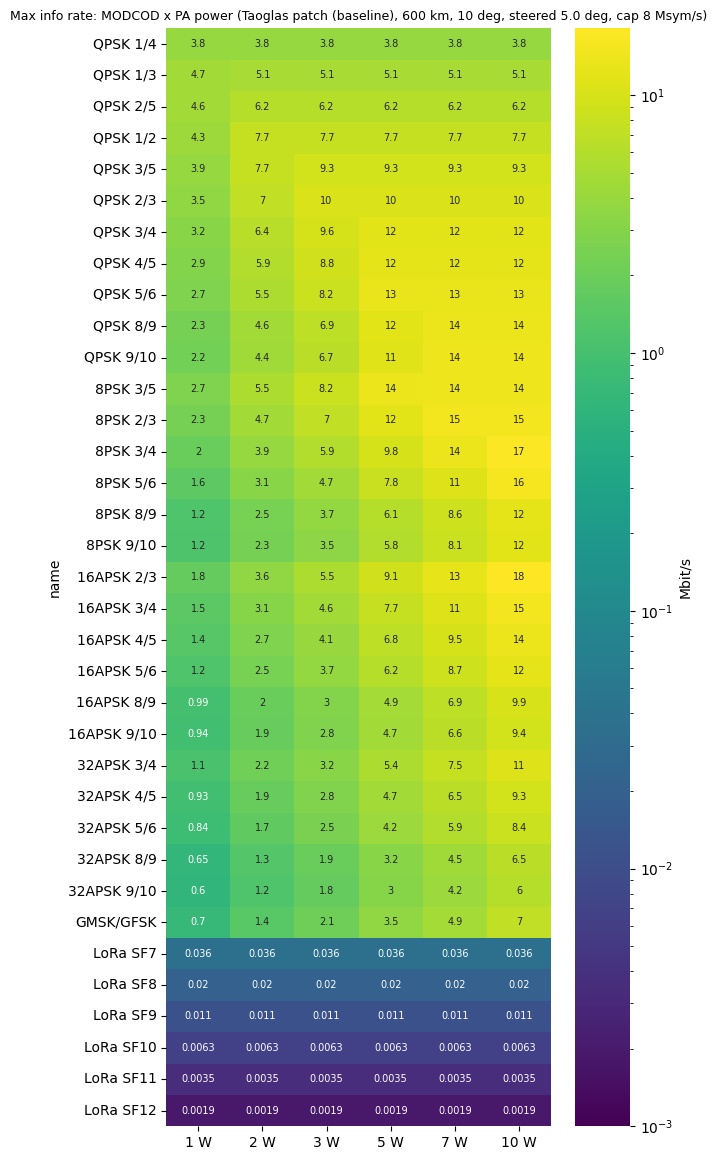

In [ ]:
def rate_heatmap(df, title, ax=None, vmin=1e-3):
    '''Annotated log-colour heatmap of a rate table in Mbit/s.'''
    d = df.clip(lower=vmin)
    txt = np.vectorize(lambda x: f"{x:.2g}" if x > vmin else "-")(df.to_numpy())
    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(max(6.5, 1.2 + 0.9*df.shape[1]), max(3.5, 0.5 + 0.32*df.shape[0])))
    sns.heatmap(d, annot=txt, fmt="", cmap="viridis", norm=LogNorm(vmin=vmin, vmax=max(d.to_numpy().max(), vmin*10)),
                cbar_kws={"label": "Mbit/s"}, annot_kws={"fontsize": 7}, ax=ax)
    ax.set_title(title, fontsize=9)
    if show:
        plt.tight_layout(); plt.show()

POWERS = [1, 2, 3, 5, 7, 10]

# ---- Sweep A: MODCOD x PA power
alt, el = TRADE["alt_km"], TRADE["eval_el_deg"]
ZA = pd.DataFrame({f"{p} W": [float(solve_mode(*prx_S(alt, el, p_W=p), m)[0])/1e6 for _, m in MODES.iterrows()] for p in POWERS},
                  index=MODES["name"])
rate_heatmap(ZA, f"Max info rate: MODCOD x PA power ({TRADE['ant']}, {alt:g} km, {el:g} deg, {TRADE['pointing']} {TRADE['pointing_err_deg']} deg, cap {TRADE['Rs_max_sps']/1e6:g} Msym/s)")

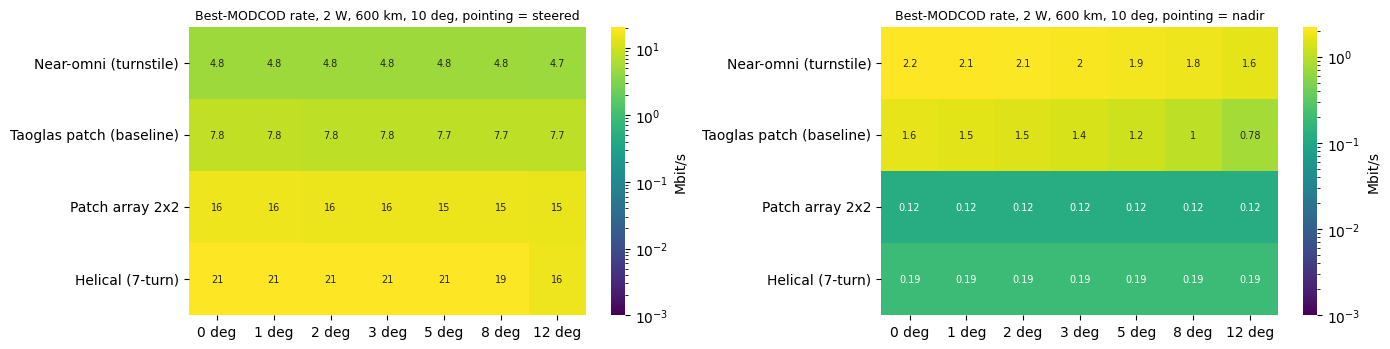

In [ ]:
# ---- Sweep B: antenna x pointing error, best MODCOD (ACM), steered vs body-fixed nadir
ERRS = [0, 1, 2, 3, 5, 8, 12]
P_B = 2.0
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, pointing in zip(axes, ("steered", "nadir")):
    ZB = pd.DataFrame({f"{e} deg": [float(best_rate_bps(*prx_S(alt, el, p_W=P_B, ant=a, err_deg=e, pointing=pointing)))/1e6
                                   for a in SAT_ANTENNAS] for e in ERRS}, index=list(SAT_ANTENNAS))
    rate_heatmap(ZB, f"Best-MODCOD rate, {P_B:g} W, {alt:g} km, {el:g} deg, pointing = {pointing}", ax=ax)
plt.tight_layout(); plt.show()

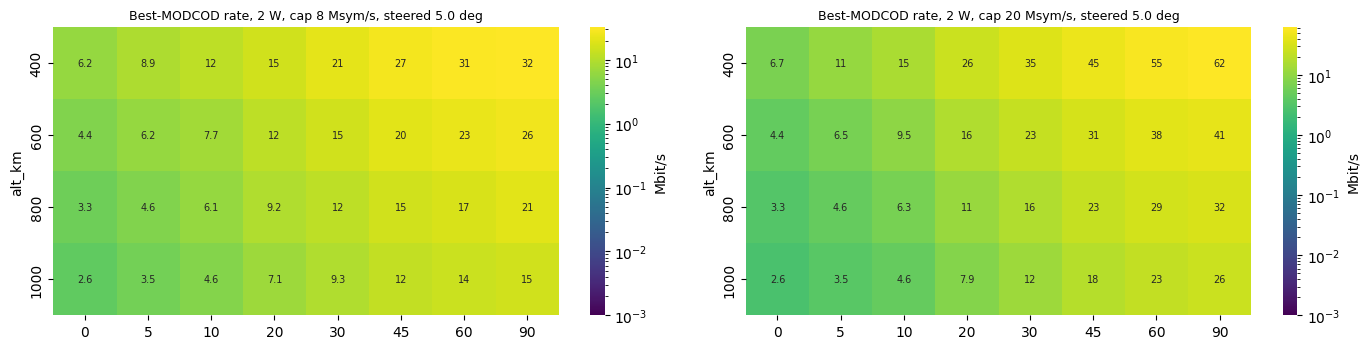

In [ ]:
# ---- Sweep C: altitude x elevation, best MODCOD, for two symbol-rate caps (v2 table style)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, cap in zip(axes, (TRADE["Rs_max_sps"], 20e6)):
    tab = pd.DataFrame({e: [float(best_rate_bps(*prx_S(h, e), Rs_cap=cap))/1e6 for h in altitudes_km] for e in elevations_degree}, index=altitudes_km)
    tab.index.name = "alt_km"
    rate_heatmap(tab, f"Best-MODCOD rate, {SAT_S['pa_out_W']:g} W, cap {cap/1e6:g} Msym/s, {TRADE['pointing']} {TRADE['pointing_err_deg']} deg", ax=ax)
plt.tight_layout(); plt.show()

# Time-domain pass integration

Step through a pass (1 s steps): elevation $\to$ range $\to$ $P_{rx}\to$ the rate each mode can close. This converts rates into honest MB per pass. The gap between **fixed** and **ACM** is what the changing geometry costs you.

In [ ]:
def simulate_pass(alt_km=None, min_el_deg=None, max_el_deg=None, dt=1.0, modes=None, margin_dB=None, Rs_cap=None, impl_dB=None, **link_kw):
    '''Returns (per-mode table, ACM MB/pass, profile, rate matrix [modes x steps])'''
    alt_km     = TRADE["alt_km"] if alt_km is None else alt_km
    min_el_deg = TRADE["min_el_deg"] if min_el_deg is None else min_el_deg
    max_el_deg = TRADE["max_el_deg"] if max_el_deg is None else max_el_deg
    modes = MODES if modes is None else modes
    prof = pass_profile(alt_km, min_el_deg, max_el_deg, dt)
    prx, tsys = prx_S(alt_km, prof["el_deg"], **link_kw)
    R = np.array([solve_mode(prx, tsys, m, margin_dB, Rs_cap, impl_dB)[0] for _, m in modes.iterrows()])
    out = pd.DataFrame(dict(mode=modes["name"].values,
                            fixed_MB=R.min(axis=1)*prof["T"]/8e6,
                            variable_MB=R.sum(axis=1)*dt/8e6))
    return out, R.max(axis=0).sum()*dt/8e6, prof, R

res, acm, prof, Rmat = simulate_pass()
print(f"Pass: {TRADE['alt_km']:g} km, peak el {TRADE['max_el_deg']:g} deg, {prof['T']/60:.1f} min | {TRADE['ant']}, {SAT_S['pa_out_W']} W, {TRADE['pointing']} {TRADE['pointing_err_deg']} deg")
print(f"ACM (best mode each step): {acm:.0f} MB/pass, {acm*TRADE['passes_per_day']/1e3:.2f} GB/day at {TRADE['passes_per_day']:g} passes/day\n")
print(res[res["mode"].str.contains("QPSK|8PSK 3/4|16APSK 3/4|GMSK|SF7")].round(1).to_string(index=False))

Pass: 600 km, peak el 45 deg, 8.1 min | Taoglas patch (baseline), 2.0 W, steered 5.0 deg
ACM (best mode each step): 840 MB/pass, 3.36 GB/day at 4 passes/day

      mode  fixed_MB  variable_MB
  QPSK 1/4     232.8        233.4
  QPSK 1/3     311.7        312.5
  QPSK 2/5     374.9        375.9
  QPSK 1/2     469.5        470.7
  QPSK 3/5     470.6        560.5
  QPSK 2/3     428.7        605.7
  QPSK 3/4     389.2        648.7
  QPSK 4/5     357.6        662.6
  QPSK 5/6     332.4        664.7
  QPSK 8/9     280.5        646.5
 QPSK 9/10     270.1        640.3
  8PSK 3/4     238.9        666.0
16APSK 3/4     187.2        555.4
 GMSK/GFSK      85.4        253.3
  LoRa SF7       2.2          2.2


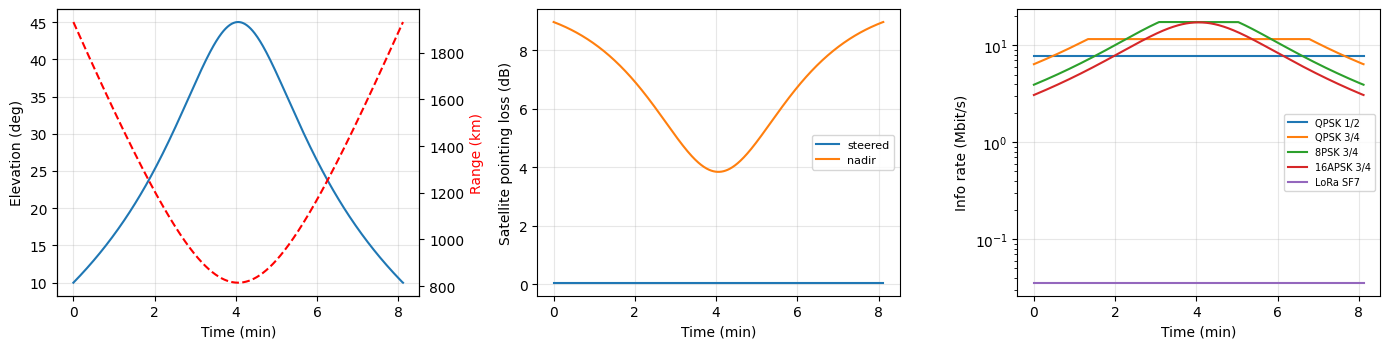

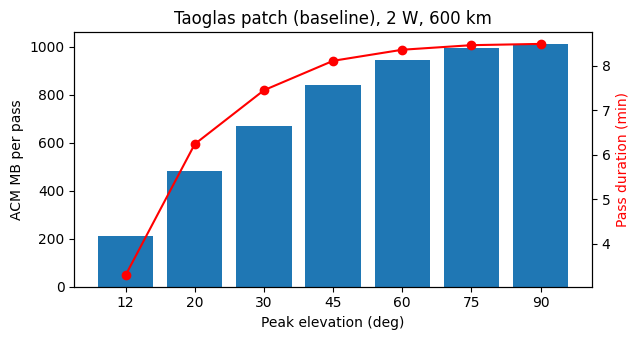

In [ ]:
# Pass picture: elevation, off-axis pointing loss, rate of a few modes
tm = prof["t"]/60
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(tm, prof["el_deg"]); ax[0].set_xlabel("Time (min)"); ax[0].set_ylabel("Elevation (deg)")
ax0b = ax[0].twinx(); ax0b.plot(tm, slant_range_km(TRADE["alt_km"], prof["el_deg"]), "r--"); ax0b.set_ylabel("Range (km)", color="r")
for pointing in ("steered", "nadir"):
    ax[1].plot(tm, sat_point_loss_db(TRADE["alt_km"], prof["el_deg"], TRADE["ant"], TRADE["pointing_err_deg"], pointing), label=pointing)
ax[1].set_xlabel("Time (min)"); ax[1].set_ylabel("Satellite pointing loss (dB)"); ax[1].legend(fontsize=8)
for nm in ("QPSK 1/2", "QPSK 3/4", "8PSK 3/4", "16APSK 3/4", "LoRa SF7"):
    i = MODES.index[MODES.name == nm][0]
    ax[2].semilogy(tm, np.maximum(Rmat[i]/1e6, 1e-4), label=nm)
ax[2].set_xlabel("Time (min)"); ax[2].set_ylabel("Info rate (Mbit/s)"); ax[2].legend(fontsize=7)
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Pass quality vs peak elevation
mes = [12, 20, 30, 45, 60, 75, 90]
vals, durs = [], []
for me in mes:
    _, a, p, _ = simulate_pass(max_el_deg=me); vals.append(a); durs.append(p["T"]/60)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar([str(x) for x in mes], vals); ax.set_xlabel("Peak elevation (deg)"); ax.set_ylabel("ACM MB per pass")
ax2 = ax.twinx(); ax2.plot([str(x) for x in mes], durs, "ro-"); ax2.set_ylabel("Pass duration (min)", color="r")
ax.set_title(f"{TRADE['ant']}, {SAT_S['pa_out_W']:g} W, {TRADE['alt_km']:g} km"); plt.tight_layout(); plt.show()

# The big matrix: data per pass and per day

Full factorial: antenna $\times$ PA power $\times$ mode, using the time-domain engine at the GNC pointing requirement. One row per combination. Columns `needs_pointing_le_deg` and `needs_PA_gt_3W` flag the cells that depend on GNC hitting the pointing requirement and on structures handling more than 3 W, which River tied to the design matrix.

In [ ]:
records = []
for ant in SAT_ANTENNAS:
    for p in POWERS:
        r, acm_v, _, _ = simulate_pass(p_W=p, ant=ant, err_deg=TRADE["gnc_req_deg"])
        for _, row in r.iterrows():
            records.append(dict(antenna=ant, power_W=p, mode=row["mode"],
                                fixed_MB_pass=row.fixed_MB, variable_MB_pass=row.variable_MB,
                                fixed_MB_day=row.fixed_MB*TRADE["passes_per_day"],
                                variable_MB_day=row.variable_MB*TRADE["passes_per_day"],
                                needs_pointing_le_deg=TRADE["gnc_req_deg"],
                                needs_PA_gt_3W=p > TRADE["pa_struct_W"]))
MATRIX = pd.DataFrame(records)
print(f"{len(MATRIX)} combinations ({TRADE['alt_km']:g} km, peak el {TRADE['max_el_deg']:g} deg, {TRADE['pointing']} pointing)\n")
print(MATRIX.sort_values("variable_MB_day", ascending=False).head(15).round(1).to_string(index=False))

840 combinations (600 km, peak el 45 deg, steered pointing)

         antenna  power_W        mode  fixed_MB_pass  variable_MB_pass  fixed_MB_day  variable_MB_day  needs_pointing_le_deg  needs_PA_gt_3W
Helical (7-turn)       10 32APSK 9/10         2120.9            2126.1        8483.4           8504.6                    5.0            True
Helical (7-turn)       10  32APSK 8/9         2094.7            2099.9        8378.6           8399.5                    5.0            True
Helical (7-turn)        7  32APSK 8/9         1627.6            2062.4        6510.2           8249.6                    5.0            True
Helical (7-turn)        7 32APSK 9/10         1516.8            2062.1        6067.3           8248.3                    5.0            True
 Patch array 2x2       10  32APSK 8/9         1517.1            2040.9        6068.5           8163.6                    5.0            True
 Patch array 2x2       10 32APSK 9/10         1413.9            2035.6        5655.6         

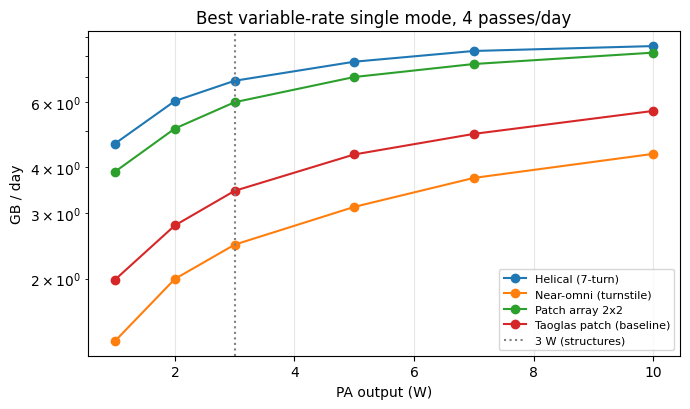

GB/day:
antenna  Helical (7-turn)  Near-omni (turnstile)  Patch array 2x2  Taoglas patch (baseline)
power_W                                                                                    
1                    4.64                   1.36             3.89                      1.99
2                    6.04                   2.00             5.09                      2.78
3                    6.85                   2.47             6.00                      3.45
5                    7.72                   3.13             7.01                      4.33
7                    8.25                   3.74             7.61                      4.92
10                   8.50                   4.35             8.16                      5.68


In [ ]:
# Best achievable MB/day (variable rate, best single mode) vs PA power for each antenna
best = MATRIX.groupby(["antenna", "power_W"]).variable_MB_day.max().unstack(0)/1e3
fig, ax = plt.subplots(figsize=(7, 4.2))
best.plot(marker="o", ax=ax)
ax.axvline(TRADE["pa_struct_W"], color="gray", ls=":", label="3 W (structures)")
ax.set_xlabel("PA output (W)"); ax.set_ylabel("GB / day"); ax.set_yscale("log"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title(f"Best variable-rate single mode, {TRADE['passes_per_day']:g} passes/day")
plt.tight_layout(); plt.show()
print("GB/day:"); print(best.round(2).to_string())

# Sensitivity (tornado)

One-at-a-time: move each input between a low and a high value with the rest at baseline and record the change in **ACM data per pass**:

$$
S_i = D_{\rm pass}\!\left(x_i^{\rm high}\right) - D_{\rm pass}\!\left(x_i^{\rm low}\right)
$$

The widest bar is the input that moves your data volume the most. Baseline here is the 2x2 patch array at 3 W, since that is the antenna where pointing error is expected to matter.

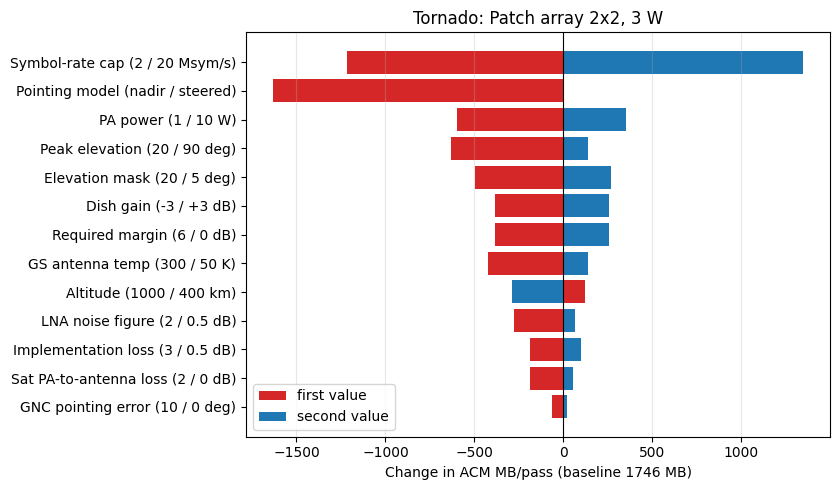

In [ ]:
BASE = dict(ant="Patch array 2x2", p_W=3.0)
base_v = simulate_pass(**BASE)[1]

def vol(**kw):
    return simulate_pass(**{**BASE, **kw})[1]

dish = GS_S["dish_gain_dBi"]
cases = {   # label: (low-case kwargs, high-case kwargs)
    "PA power (1 / 10 W)":                 (dict(p_W=1.0),            dict(p_W=10.0)),
    "GNC pointing error (10 / 0 deg)":     (dict(err_deg=10.0),       dict(err_deg=0.0)),
    "Dish gain (-3 / +3 dB)":              (dict(g=dict(GS_S, dish_gain_dBi=dish-3)), dict(g=dict(GS_S, dish_gain_dBi=dish+3))),
    "GS antenna temp (300 / 50 K)":        (dict(g=dict(GS_S, T_ant_K=300)),          dict(g=dict(GS_S, T_ant_K=50))),
    "LNA noise figure (2 / 0.5 dB)":       (dict(g=dict(GS_S, lna_nf_dB=2.0)),        dict(g=dict(GS_S, lna_nf_dB=0.5))),
    "Required margin (6 / 0 dB)":          (dict(margin_dB=6.0),      dict(margin_dB=0.0)),
    "Implementation loss (3 / 0.5 dB)":    (dict(impl_dB=3.0),        dict(impl_dB=0.5)),
    "Sat PA-to-antenna loss (2 / 0 dB)":   (dict(sat=dict(SAT_S, loss_dB=2.0)),       dict(sat=dict(SAT_S, loss_dB=0.0))),
    "Symbol-rate cap (2 / 20 Msym/s)":     (dict(Rs_cap=2e6),         dict(Rs_cap=20e6)),
    "Altitude (1000 / 400 km)":            (dict(alt_km=1000.0),      dict(alt_km=400.0)),
    "Elevation mask (20 / 5 deg)":         (dict(min_el_deg=20.0),    dict(min_el_deg=5.0)),
    "Peak elevation (20 / 90 deg)":        (dict(max_el_deg=20.0),    dict(max_el_deg=90.0)),
    "Pointing model (nadir / steered)":    (dict(pointing="nadir"),   dict(pointing="steered")),
}
rows = [(k, vol(**lo) - base_v, vol(**hi) - base_v) for k, (lo, hi) in cases.items()]
tor = pd.DataFrame(rows, columns=["param", "low", "high"])
tor["span"] = (tor.high - tor.low).abs()
tor = tor.sort_values("span")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(tor.param, tor.low, color="tab:red", label="first value")
ax.barh(tor.param, tor.high, color="tab:blue", label="second value")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel(f"Change in ACM MB/pass (baseline {base_v:.0f} MB)"); ax.set_title(f"Tornado: {BASE['ant']}, {BASE['p_W']:g} W")
ax.legend(); ax.grid(alpha=0.3, axis="x"); plt.tight_layout(); plt.show()

# Monte Carlo

Same approach as v2 (random terms passed into the link equation, losses clipped at 0 dB), with one change: the tumbling-patch spread is replaced by an explicit **GNC pointing error**.

- `pointing_sigma_deg`: Rayleigh-distributed pointing error (magnitude, so $\ge 0$). PLACEHOLDER 2 deg: replace with GNC's real distribution.
- `sat_ant_std_dB`: gain tolerance only, 1 dB. (In v2 this was 3 dB because it also stood in for pointing; keeping both would double count.)
- `dish_gain_std_dB`, `point_std_dB` (dish), `tsys_std_K`, `pa_std_dB`, `atm_std_dB`: as in v2.

Margin for a chosen MODCOD and symbol rate:

$$
M = P_{rx} - \left[N_0(T_{\rm sys}) + 10\log_{10}R_s + (E_s/N_0)_{\rm req} + L_{\rm impl}\right]
$$

Report $P(M > 6\,\mathrm{dB})$ (same target as v2's heatmaps).

In [ ]:
def monte_carlo_margin_S_trade(alt_km, elev_deg, modcod, Rs, p_W=None, ant=None, pointing=None, n=20000, seed=0,
                               pointing_sigma_deg=2.0, sat_ant_std_dB=1.0, dish_gain_std_dB=1.0, point_std_dB=2.5,
                               tsys_std_K=30.0, pa_std_dB=0.5, atm_std_dB=0.1):
    rng = np.random.default_rng(seed)
    ant = ant or TRADE["ant"]
    s0 = build_s_spec(dict(SAT_S, ant_gain_dBi=SAT_ANTENNAS[ant][0], **({"pa_out_W": p_W} if p_W else {})))
    err = pointing_sigma_deg*np.sqrt(-2*np.log(1 - rng.random(n)))          # Rayleigh GNC error [deg]
    ov = dict(
        tx_power_dBm = s0["tx_power_dBm"] + rng.normal(0, pa_std_dB, n),
        tx_gain_dBi  = s0["tx_gain_dBi"]  + rng.normal(0, sat_ant_std_dB, n),
        rx_gain_dBi  = s0["rx_gain_dBi"]  + rng.normal(0, dish_gain_std_dB, n),
        L_point_dB   = loss_sample(rng, s0["L_point_dB"], point_std_dB, n),
        L_atm_dB     = s0["L_atm_dB"] + np.abs(rng.normal(0, atm_std_dB, n)),
    )
    prx, tsys0 = prx_S(alt_km, elev_deg, p_W=p_W, ant=ant, err_deg=err, pointing=pointing, **ov)
    tsys = np.clip(tsys0 + rng.normal(0, tsys_std_K, n), 30, None)
    return prx - (therm_noise_dbm(tsys, Rs) + MODE[modcod]["thr_dB"] + DVB_S2["impl_loss_dB"])

def p_target_grid(altitudes, elevations, mc_func, target=6.0, **kwargs):
    grid = np.zeros((len(altitudes), len(elevations)))
    for i, h in enumerate(altitudes):
        for j, e in enumerate(elevations):
            m = mc_func(h, e, **kwargs)
            grid[i, j] = 100*(m > target).mean()
    return pd.DataFrame(grid, index=altitudes, columns=elevations)

def plot_heatmaps(dfs, titles, label="P(>6dB) %"):
    fig, axes = plt.subplots(1, len(dfs), figsize=(6.5*len(dfs), 4.5))
    axes = np.atleast_1d(axes)
    for ax, d, title in zip(axes, dfs, titles):
        sns.heatmap(d, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100,
                    cbar_kws={"label": label}, ax=ax)
        ax.set_xlabel("Elevation (deg)"); ax.set_ylabel("Altitude (km)"); ax.set_title(title, fontsize=9)
    plt.tight_layout(); plt.show()

River-class case: 8PSK 3/4 at 7.35 Msym/s -> 16 Mbit/s


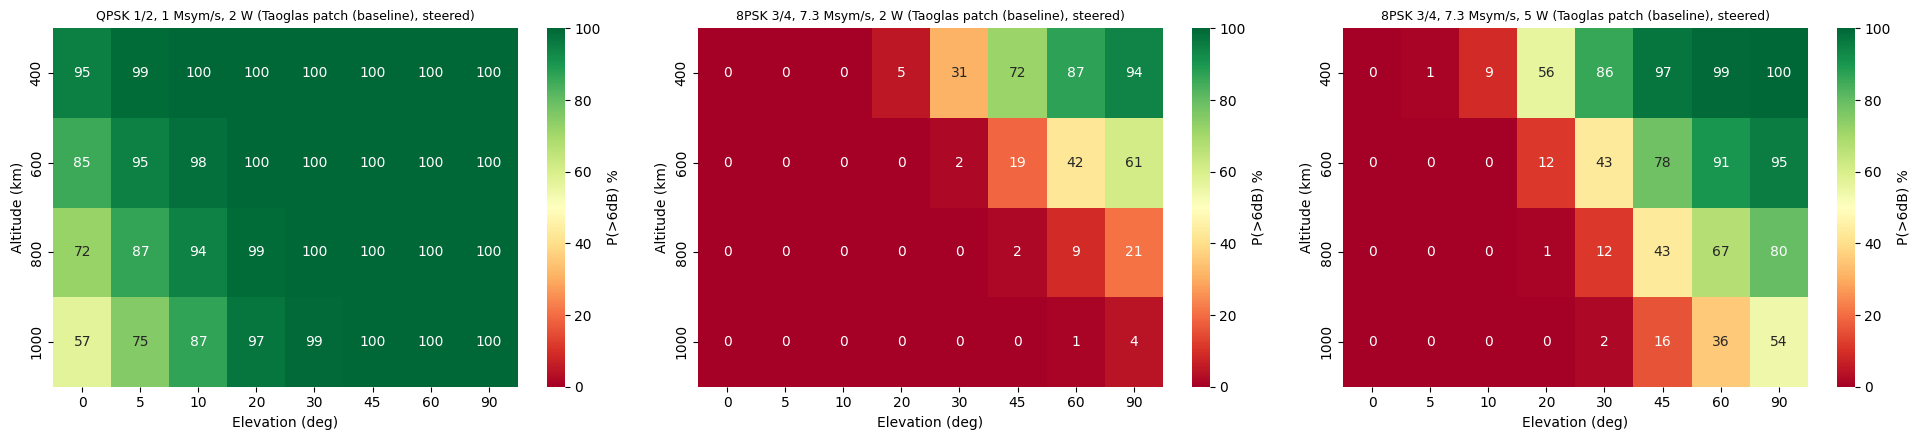


P(margin > 6 dB) [%]: QPSK 1/2, 1 Msym/s, 2 W
        0     5     10     20     30     45     60     90
400   95.2  99.0  99.8  100.0  100.0  100.0  100.0  100.0
600   85.5  94.7  98.3   99.9  100.0  100.0  100.0  100.0
800   72.2  86.5  94.2   99.2   99.9  100.0  100.0  100.0
1000  57.2  75.1  86.9   97.0   99.4   99.9  100.0  100.0

P(margin > 6 dB) [%]: 8PSK 3/4, 7.3 Msym/s, 2 W
       0    5    10   20    30    45    60    90
400   0.0  0.0  0.0  4.7  31.2  71.8  87.3  93.8
600   0.0  0.0  0.0  0.1   1.8  19.0  42.3  61.2
800   0.0  0.0  0.0  0.0   0.1   1.8   9.4  21.1
1000  0.0  0.0  0.0  0.0   0.0   0.1   1.1   4.0

P(margin > 6 dB) [%]: 8PSK 3/4, 7.3 Msym/s, 5 W
       0    5    10    20    30    45    60    90
400   0.0  1.0  9.1  56.1  86.0  97.2  99.3  99.8
600   0.0  0.0  0.4  11.7  43.0  78.2  90.5  95.3
800   0.0  0.0  0.0   1.2  11.6  43.1  67.0  79.9
1000  0.0  0.0  0.0   0.1   1.8  15.8  35.9  53.9


In [ ]:
# Case 1: v2 baseline waveform (QPSK 1/2, 1 Msym/s) at 2 W, with explicit GNC error
# Case 2: River-class rate (16 Mbit/s) with the lowest-order DVB-S2 MODCOD that fits under the symbol-rate cap, at 2 W and 5 W
fits = df_river[df_river.under_cap].sort_values("Rs_needed_Msps")
river_mc = min(fits["mode"], key=lambda n: MODE[n]["thr_dB"])   # lowest-threshold (most robust) MODCOD that still reaches 16 Mbit/s under the cap
river_Rs = R_TARGET_BPS/(MODE[river_mc]["eta"]*MODE[river_mc]["pilot_f"])
print(f"River-class case: {river_mc} at {river_Rs/1e6:.2f} Msym/s -> 16 Mbit/s")

cases_mc = [
    ("QPSK 1/2, 1 Msym/s, 2 W",                          dict(modcod="QPSK 1/2", Rs=1e6, p_W=2.0)),
    (f"{river_mc}, {river_Rs/1e6:.1f} Msym/s, 2 W",       dict(modcod=river_mc, Rs=river_Rs, p_W=2.0)),
    (f"{river_mc}, {river_Rs/1e6:.1f} Msym/s, 5 W",       dict(modcod=river_mc, Rs=river_Rs, p_W=5.0)),
]
grids = [p_target_grid(altitudes_km, elevations_degree, monte_carlo_margin_S_trade, **kw) for _, kw in cases_mc]
plot_heatmaps(grids, [f"{lbl} ({TRADE['ant']}, {TRADE['pointing']})" for lbl, _ in cases_mc])
for (lbl, _), g_ in zip(cases_mc, grids):
    print(f"\nP(margin > 6 dB) [%]: {lbl}"); print(g_.round(1).to_string())

In [ ]:
# Does pointing model matter? Same MODCOD, 600 km, 10 deg: steered (GNC) vs body-fixed nadir, patch vs 2x2 array
rows = []
for ant in ("Taoglas patch (baseline)", "Patch array 2x2", "Helical (7-turn)"):
    for pointing in ("steered", "nadir"):
        m = monte_carlo_margin_S_trade(600, 10, "QPSK 1/2", 1e6, ant=ant, pointing=pointing)
        rows.append(dict(antenna=ant, pointing=pointing, median_dB=np.median(m), p5_dB=np.percentile(m, 5),
                         P_gt_6dB=100*(m > 6).mean(), P_gt_0dB=100*(m > 0).mean()))
print("QPSK 1/2, 1 Msym/s, 2 W, 600 km, 10 deg")
print(pd.DataFrame(rows).round(1).to_string(index=False))

QPSK 1/2, 1 Msym/s, 2 W, 600 km, 10 deg
                 antenna pointing  median_dB  p5_dB  P_gt_6dB  P_gt_0dB
Taoglas patch (baseline)  steered       12.1    7.5      98.3     100.0
Taoglas patch (baseline)    nadir        3.8   -0.8      16.3      91.8
         Patch array 2x2  steered       18.0   13.5     100.0     100.0
         Patch array 2x2    nadir       -6.9  -11.4       0.0       0.0
        Helical (7-turn)  steered       20.0   15.4     100.0     100.0
        Helical (7-turn)    nadir       -4.9   -9.4       0.0       1.0


# Pareto filter and export

Reduce the matrix to a short list for the design matrix. Design $A$ **dominates** $B$ if it is at least as good in every objective and strictly better in one:

$$
A \succ B \iff \forall i:\ f_i(A) \preceq f_i(B)\ \wedge\ \exists j:\ f_j(A) \prec f_j(B)
$$

Objectives: maximize $D_{\rm day}$, minimize PA power, minimize complexity. **Complexity scores are team judgment** (1 = simple, 5 = hard): edit the dictionaries. Add more objectives (mass, DC power, cost) as columns.

In [ ]:
MOD_COMPLEXITY = {"QPSK": 1, "8PSK": 2, "16APSK": 3, "32APSK": 4, "GMSK": 1, "LoRa": 1}          # PLACEHOLDER scores
ANT_COMPLEXITY = {"Near-omni (turnstile)": 1, "Taoglas patch (baseline)": 1, "Patch array 2x2": 2, "Helical (7-turn)": 3}

M = MATRIX.copy()
M["complexity"] = M["mode"].map(lambda s: MOD_COMPLEXITY[s.split()[0].split("/")[0]]) + M["antenna"].map(ANT_COMPLEXITY)
M = M[M.variable_MB_day > 0].reset_index(drop=True)

def pareto_mask(df, maximize, minimize):
    X = np.column_stack([-df[c] for c in maximize] + [df[c] for c in minimize])
    keep = np.ones(len(df), bool)
    for i in range(len(df)):
        dom = np.all(X <= X[i], axis=1) & np.any(X < X[i], axis=1)
        if dom.any():
            keep[i] = False
    return keep

front = M[pareto_mask(M, ["variable_MB_day"], ["power_W", "complexity"])]
print(front.sort_values("variable_MB_day", ascending=False).round(1).head(25).to_string(index=False))
print(f"\n{len(front)} Pareto-optimal of {len(M)} viable combinations")

MATRIX.to_csv("downlink_trade_matrix.csv", index=False)
front.to_csv("downlink_pareto_front.csv", index=False)
try:
    from google.colab import files
    files.download("downlink_trade_matrix.csv"); files.download("downlink_pareto_front.csv")
except ImportError:
    pass

                 antenna  power_W        mode  fixed_MB_pass  variable_MB_pass  fixed_MB_day  variable_MB_day  needs_pointing_le_deg  needs_PA_gt_3W  complexity
        Helical (7-turn)       10 32APSK 9/10         2120.9            2126.1        8483.4           8504.6                    5.0            True           7
        Helical (7-turn)        7  32APSK 8/9         1627.6            2062.4        6510.2           8249.6                    5.0            True           7
         Patch array 2x2       10  32APSK 8/9         1517.1            2040.9        6068.5           8163.6                    5.0            True           6
        Helical (7-turn)        5  32APSK 5/6         1506.8            1928.9        6027.1           7715.6                    5.0            True           7
         Patch array 2x2        7  32APSK 5/6         1376.4            1901.5        5505.8           7605.9                    5.0            True           6
         Patch array 2x2        5 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Need to knows:

- **Ask River:** altitude(s), GS location, symbol-rate cap of the RP2350/AFE7071 chain, and whether the SX1280/GMSK floor modes are in scope (v2 removed S-band LoRa from the baseline).
- **Replace `passes_per_day`** with a real count: propagate a TLE with `skyfield`/`sgp4` for the GS and count passes above the mask. The elevation profile from that can be fed straight into `prx_S`.
- **Replace the parabolic pointing-loss model** with a measured or simulated pattern (HFSS/openEMS) once antennas are chosen. The Taoglas beamwidth in `SAT_ANTENNAS` is a placeholder.
- **DVB-S2 8PSK/APSK:** `INCLUDE_HIGH_ORDER=False` restricts the study to QPSK. Check the gr-dvbs2rx/RP2350 chain actually supports the higher orders before using them in the design matrix.
- **Simplifications to document next to the results:** circular orbit, no Earth rotation, constant GS antenna temperature, AWGN only, no Doppler/frequency-offset loss, constant atmospheric loss.
- v2 resources (ITU-R P.618, link budget references) still apply.